In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020/ai4i2020.csv


In [2]:
df= pd.read_csv('/kaggle/input/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020/ai4i2020.csv')
#print(df.head())
print(df.shape)
#print(df.columns.tolist())
print(df.describe())

(10000, 14)
               UDI  Air temperature [K]  Process temperature [K]  \
count  10000.00000         10000.000000             10000.000000   
mean    5000.50000           300.004930               310.005560   
std     2886.89568             2.000259                 1.483734   
min        1.00000           295.300000               305.700000   
25%     2500.75000           298.300000               308.800000   
50%     5000.50000           300.100000               310.100000   
75%     7500.25000           301.500000               311.100000   
max    10000.00000           304.500000               313.800000   

       Rotational speed [rpm]   Torque [Nm]  Tool wear [min]  Machine failure  \
count            10000.000000  10000.000000     10000.000000     10000.000000   
mean              1538.776100     39.986910       107.951000         0.033900   
std                179.284096      9.968934        63.654147         0.180981   
min               1168.000000      3.800000        

fit into weibull distribution

In [3]:
!pip install reliability

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 257.2/257.2 kB 6.1 MB/s eta 0:00:00:00:01
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=60ab5d948e0e71eeb33dfac8ed779705dde3ba22b75cac76305333ec138e085a
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma


Results from Fit_Weibull_2P (95% CI):
Analysis method: Maximum Likelihood Estimation (MLE)
Optimizer: TNC
Failures / Right censored: 46/9834 (99.53441% right censored) 

Parameter  Point Estimate  Standard Error  Lower CI  Upper CI
    Alpha         246.889         2.27723   242.466   251.393
     Beta          23.637          1.7616   20.4247   27.3546 

Goodness of fit    Value
 Log-likelihood -292.911
           AICc  589.823
            BIC  604.218
             AD  80.3239 

Beta: 23.6370
Eta: 246.8894 mins


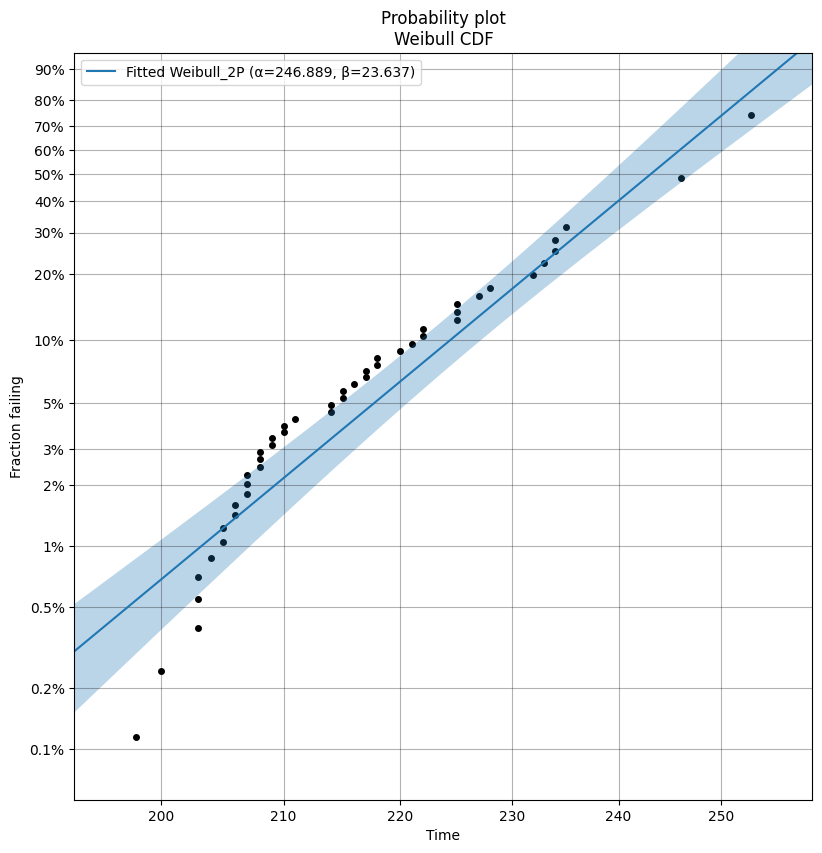

In [4]:
import pandas as pd
from reliability.Fitters import Fit_Weibull_2P


failed = df[df['TWF'] == 1]['Tool wear [min]'].values
censored = df[df['TWF'] == 0]['Tool wear [min]'].values

wb = Fit_Weibull_2P(
    failures=failed,
    right_censored=censored,
    print_results=True,
    show_probability_plot=True
)

print(f"Beta: {wb.beta:.4f}")
print(f"Eta: {wb.alpha:.4f} mins")

Diffrent for L,H and M

Machine Type  β (shape)  η (scale, min)  No. Failed  No. Censored
           L    22.5932         249.782          25          5975
           M    25.6398         242.758          14          2983
           H    22.7743         245.108           7           996
120


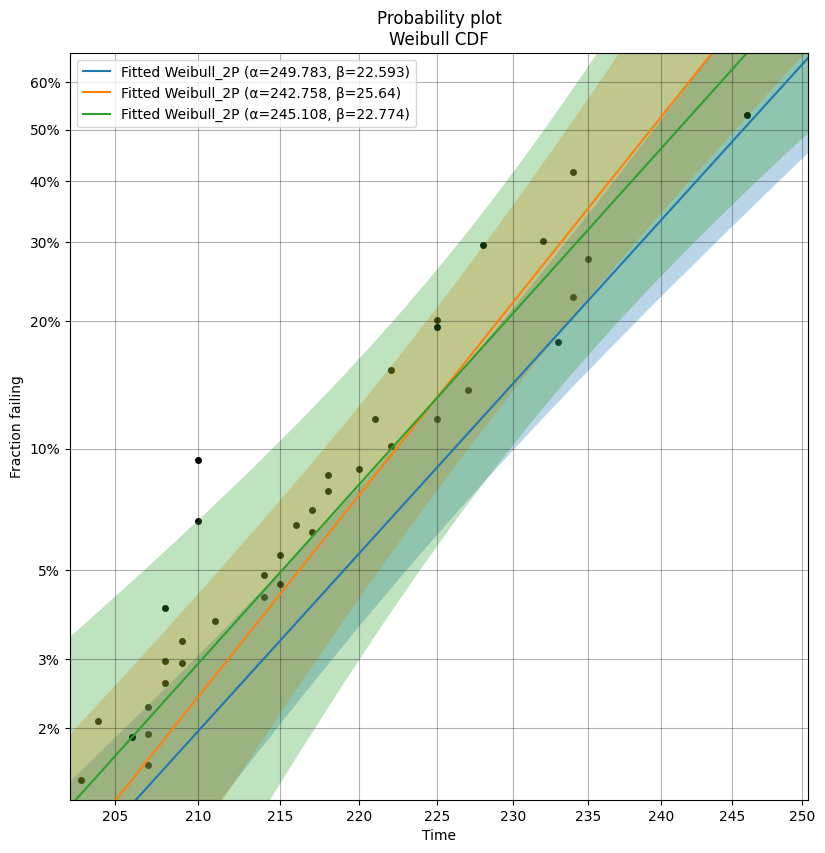

In [5]:
import pandas as pd
from reliability.Fitters import Fit_Weibull_2P

results = []

for t in ['L', 'M', 'H']:
    sub = df[df['Type'] == t]
    
    failed   = sub[sub['TWF'] == 1]['Tool wear [min]'].values
    censored = sub[sub['TWF'] == 0]['Tool wear [min]'].values
    
    wb = Fit_Weibull_2P(failures=failed, right_censored=censored, print_results=False)
    
    results.append({
        'Machine Type'      : t,
        'β (shape)'         : round(wb.beta, 4),
        'η (scale, min)'    : round(wb.alpha, 4),
        'No. Failed'        : len(failed),
        'No. Censored'      : len(censored),
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))
print(df[df['Tool wear [min]'] == 0].shape[0])


Weibull regression 

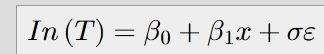

In [6]:
!pip install lifelines

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 11.0 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 6.6 MB/s eta 0:00:00


Regression without considering type as a covariate 

<lifelines.WeibullAFTFitter: fitted with 9880 total observations, 9544 right-censored observations>
             duration col = 'Tool wear [min]'
                event col = 'Machine failure'
   number of observations = 9880
number of events observed = 336
           log-likelihood = -2501.05
         time fit was run = 2026-06-14 19:36:47 UTC

---
                                 coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param   covariate                                                                                                                
lambda_ Air temperature [K]     -0.22      0.80      0.02           -0.27           -0.17                0.77                0.84
        Process temperature [K]  0.20      1.23      0.03            0.14            0.27                1.15                1.31
        Rotational speed [rpm]  -0.00      1.00      0.00           -0.00           -0.00                1.00                1.00
        Torque [Nm]             -0.08      0.93      0.00           -0.09           -0.07                0.92                0.93
        Intercept               16.32  1.23e+07      4.91            6.70           25.94              814.24            1.85e+11
rho_    Intercept                0.96      2.62      0.04            0.88            1.05                2.41                2.86

                                 cmp to      z      p  -log2(p)
param   covariate                                              
lambda_ Air temperature [K]        0.00  -8.89 <0.005     60.51
        Process temperature [K]    0.00   6.40 <0.005     32.55
        Rotational speed [rpm]     0.00 -16.56 <0.005    202.22
        Torque [Nm]                0.00 -17.84 <0.005    234.19
        Intercept                  0.00   3.33 <0.005     10.15
rho_    Intercept                  0.00  22.14 <0.005    358.45
---
Concordance = 0.92
AIC = 5014.10
log-likelihood ratio test = 766.17 on 4 df
-log2(p) of ll-ratio test = 544.09

<Axes: xlabel='log(accelerated failure rate) (95% CI)'>

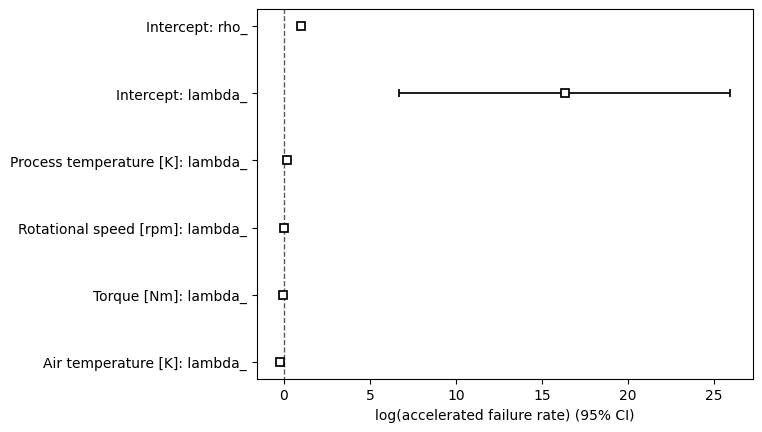

In [7]:
import pandas as pd
import numpy as np
from lifelines import WeibullAFTFitter

df_clean = df[df['Tool wear [min]'] > 0].copy()

df_model = df_clean[[
    'Tool wear [min]',
    'Machine failure',
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
]].copy()


aft = WeibullAFTFitter()
aft.fit(df_model, duration_col='Tool wear [min]', event_col='Machine failure')

aft.print_summary()
# summary = aft.summary[['coef', 'p']].copy()
# summary.columns = ['β',  'p-value']
# print(summary.round(6).to_string())
aft.plot()

Regression WITH considering type as a covariate 

<lifelines.WeibullAFTFitter: fitted with 9880 total observations, 9544 right-censored observations>
             duration col = 'Tool wear [min]'
                event col = 'Machine failure'
   number of observations = 9880
number of events observed = 336
           log-likelihood = -2498.04
         time fit was run = 2026-06-14 19:36:48 UTC

---
                                 coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param   covariate                                                                                                                
lambda_ Air temperature [K]     -0.22      0.81      0.02           -0.26           -0.17                0.77                0.85
        Process temperature [K]  0.20      1.22      0.03            0.14            0.26                1.15                1.30
        Rotational speed [rpm]  -0.00      1.00      0.00           -0.00           -0.00                1.00                1.00
        Torque [Nm]             -0.08      0.93      0.00           -0.09           -0.07                0.92                0.93
        Type_H                   0.19      1.21      0.09            0.02            0.36                1.02                1.43
        Type_M                   0.06      1.06      0.05           -0.04            0.16                0.97                1.17
        Intercept               16.64  1.69e+07      4.93            6.99           26.30             1080.56            2.65e+11
rho_    Intercept                0.96      2.62      0.04            0.88            1.05                2.40                2.85

                                 cmp to      z      p  -log2(p)
param   covariate                                              
lambda_ Air temperature [K]        0.00  -8.81 <0.005     59.49
        Process temperature [K]    0.00   6.29 <0.005     31.56
        Rotational speed [rpm]     0.00 -16.48 <0.005    200.31
        Torque [Nm]                0.00 -17.77 <0.005    232.33
        Type_H                     0.00   2.14   0.03      4.94
        Type_M                     0.00   1.24   0.21      2.22
        Intercept                  0.00   3.38 <0.005     10.42
rho_    Intercept                  0.00  22.06 <0.005    355.69
---
Concordance = 0.92
AIC = 5012.07
log-likelihood ratio test = 772.20 on 6 df
-log2(p) of ll-ratio test = 540.83

<Axes: xlabel='log(accelerated failure rate) (95% CI)'>

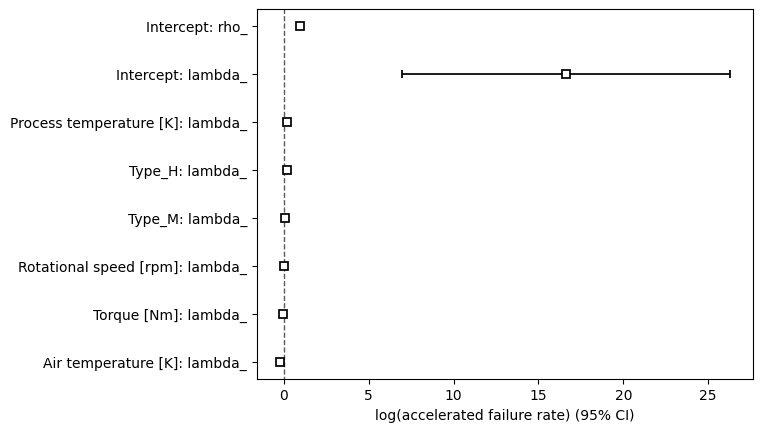

In [8]:
import pandas as pd
from lifelines import WeibullAFTFitter


df_with_type = df_clean[[
    'Tool wear [min]',
    'Machine failure',
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Type'                   
]].copy()


type_dummies = pd.get_dummies(df_with_type['Type'], prefix='Type')
df_with_type = pd.concat([df_with_type, type_dummies], axis=1)


df_with_type.drop(columns=['Type', 'Type_L'], inplace=True)   

aft_with_type = WeibullAFTFitter()
aft_with_type.fit(df_with_type, 
                  duration_col='Tool wear [min]', 
                  event_col='Machine failure')


aft_with_type.print_summary()
aft_with_type.plot()

# Weibull Regression(WB(alpha, beta)) with alpha and beta where beta_i = exp ( gamma_0  + gamma_1* x_i )

In [9]:
import numpy as np

def generate_synthetic_data(n=20, true_alpha=2.5, true_g0=0.5, true_g1=1.2, seed=42):
    """Generates synthetic Weibull data with covariate x."""
    np.random.seed(seed)
    x = np.random.uniform(0, 1, n)
    
    # beta_i = exp(gamma_0 + gamma_1 * x_i)
    beta_true = np.exp(true_g0 + true_g1 * x)
    
    # np.random.weibull takes the shape parameter (beta). 
    # To apply the scale parameter (alpha), we multiply the result by alpha.
    t = true_alpha * np.random.weibull(beta_true)
    
    return t, x

def method1_newton_raphson(t, x, init_params, tol=1e-6, max_iter=100):
    """
    Method 1: Brute Force (Newton-Raphson)
    Updates using: theta_{k+1} = theta_k - J^{-1} F(theta_k)
    """
    alpha, g0, g1 = init_params
    
    for i in range(max_iter):
        beta = np.exp(g0 + g1 * x)
        A = (t / alpha) ** beta
        ln_t_alpha = np.log(t / alpha)
        
        # 1. Gradients F (First derivatives of log-likelihood)
        dl_da = -(1 / alpha) * np.sum(beta * (1 - A))
        dl_dg0 = np.sum(1 + beta * ln_t_alpha * (1 - A))
        dl_dg1 = np.sum(x * (1 + beta * ln_t_alpha * (1 - A)))
        
        grad = np.array([dl_da, dl_dg0, dl_dg1])
        
        if np.linalg.norm(grad) < tol:
            print(f"Newton-Raphson converged in {i} iterations.")
            break
            
        # 2. Jacobian / Hessian Matrix J (Second derivatives)
        # To keep it clean, let's define a common term: D_i
        D = 1 - A - beta * A * ln_t_alpha
        
        H11 = (1 / alpha**2) * np.sum(beta * (1 - A - beta * A))
        H12 = -(1 / alpha) * np.sum(beta * D)
        H13 = -(1 / alpha) * np.sum(x * beta * D)
        
        H22 = np.sum(beta * ln_t_alpha * D)
        H23 = np.sum(x * beta * ln_t_alpha * D)
        H33 = np.sum(x**2 * beta * ln_t_alpha * D)
        
        H = np.array([
            [H11, H12, H13],
            [H12, H22, H23],
            [H13, H23, H33]
        ])
        
        # 3. Update Step: theta_{k+1} = theta_k - H^{-1} * grad
        try:
            step = np.linalg.solve(H, grad)
        except np.linalg.LinAlgError:
            print("Jacobian is singular, stopping early.")
            break
            
        alpha -= step[0]
        g0 -= step[1]
        g1 -= step[2]
        
        # Safeguard to ensure scale parameter alpha remains positive
        if alpha <= 0: 
            alpha = 1e-3

    return np.array([alpha, g0, g1])

def method2_gradient_descent(t, x, init_params, lr=1e-3, tol=1e-6, max_iter=50000):
    """
    Method 2: Gradient Descent
    Updates using: theta_{k+1} = theta_k - lr * g
    Minimizes the Negative Log-Likelihood.
    """
    alpha, g0, g1 = init_params
    
    for i in range(max_iter):
        beta = np.exp(g0 + g1 * x)
        A = (t / alpha) ** beta
        ln_t_alpha = np.log(t / alpha)
        
        # Gradients of Negative Log-Likelihood (g1, g2, g3 from your notes)
        g_alpha = (1 / alpha) * np.sum(beta * (1 - A))
        g_g0 = -np.sum(1 + beta * ln_t_alpha * (1 - A))
        g_g1 = -np.sum(x * (1 + beta * ln_t_alpha * (1 - A)))
        
        grad = np.array([g_alpha, g_g0, g_g1])
        
        if np.linalg.norm(grad) < tol:
            print(f"Gradient Descent converged in {i} iterations.")
            break
            
        # Update Step
        alpha -= lr * g_alpha
        g0 -= lr * g_g0
        g1 -= lr * g_g1
        
        # Safeguard
        if alpha <= 0: 
            alpha = 1e-3

    return np.array([alpha, g0, g1])

# --- Execution and Comparison ---
if __name__ == "__main__":
    # 1. Generate Dataset
    print("Generating synthetic dataset (n=20)...")
    t, x = generate_synthetic_data(n=20)
    
    # 2. Initial guesses (starting slightly off from true values)
    initial_guess = [2.0, 0.0, 1.0] 
    
    # 3. Run Method 1
    print("\n--- Running Method 1: Newton-Raphson ---")
    mle_nr = method1_newton_raphson(t, x, init_params=initial_guess.copy())
    print(f"Estimated Alpha : {mle_nr[0]:.10f}")
    print(f"Estimated Gamma0: {mle_nr[1]:.10f}")
    print(f"Estimated Gamma1: {mle_nr[2]:.10f}")

    # 4. Run Method 2
    # Note: GD needs a highly conservative learning rate for exponential parameters
    print("\n--- Running Method 2: Gradient Descent ---")
    mle_gd = method2_gradient_descent(t, x, init_params=initial_guess.copy(), lr=0.001)
    print(f"Estimated Alpha : {mle_gd[0]:.10f}")
    print(f"Estimated Gamma0: {mle_gd[1]:.10f}")
    print(f"Estimated Gamma1: {mle_gd[2]:.10f}")

    # 5. Conclusion
    print("\n--- Conclusion ---")
    diff = np.linalg.norm(mle_nr - mle_gd)
    if diff < 1e-4:
        print("Success! Both methods converged to the same MLE estimates.")
    else:
        print(f"Methods differed by a norm of {diff:.6f}. (Gradient descent may need more iterations or a tuned learning rate).")

Generating synthetic dataset (n=20)...

--- Running Method 1: Newton-Raphson ---
Newton-Raphson converged in 7 iterations.
Estimated Alpha : 2.0894356532
Estimated Gamma0: 0.2560561174
Estimated Gamma1: 1.7855178168

--- Running Method 2: Gradient Descent ---
Gradient Descent converged in 7337 iterations.
Estimated Alpha : 2.0894357280
Estimated Gamma0: 0.2560563370
Estimated Gamma1: 1.7855173235

--- Conclusion ---
Success! Both methods converged to the same MLE estimates.


#  More Covariates and Censored Data(MLE Change)

In [10]:
import numpy as np

# ==========================================
# 1. CLEAN & COHESIVE DATASET
# ==========================================
np.random.seed(42)
n = 100 
# True parameters (clean, simple numbers)
true_alpha = 100.0  
x1 = np.random.uniform(0, 1, n)  # e.g., Machine Load percentage
x2 = np.random.uniform(0, 1, n)  # e.g., Humidity percentage

X = np.column_stack((np.ones(n), x1, x2))

# True parameters (Clean, simple numbers)true_alpha = 100.0  
true_gamma = np.array([1.0, 0.5, -0.5]) 

# Generate survival times
true_beta = np.exp(X @ true_gamma)
u = np.random.uniform(0, 1, n)
t_true = true_alpha * (-np.log(1 - u)) ** (1 / true_beta)

# Gentle right-censoring (~20% censored)
censor_times = np.random.uniform(true_alpha * 0.5, true_alpha * 2.0, n)
t = np.minimum(t_true, censor_times)
delta = (t_true <= censor_times).astype(int)

print(f"Total Observations: {n} | Failures: {sum(delta)} | Censored: {n - sum(delta)}\n")

# ==========================================
# 2. THE DERIVED MATH (Helper Function)
# ==========================================
def calculate_terms(alpha, gamma, X, t, delta):
    beta = np.exp(X @ gamma)
    A = (t / alpha) ** beta
    D = delta - A - beta * A * np.log(t / alpha)
    return beta, A, D

# ==========================================
# 3. NEWTON-RAPHSON 
# ==========================================
def newton_raphson(X, t, delta, init_alpha, init_gamma, max_iter=100, tol=1e-5):
    alpha = init_alpha
    gamma = init_gamma.copy()
    
    for i in range(max_iter):
        beta, A, D = calculate_terms(alpha, gamma, X, t, delta)
        
        # Gradients
        F_alpha = -(1 / alpha) * np.sum(beta * (delta - A))
        F_gamma = X.T @ (delta + beta * (delta - A) * np.log(t / alpha))
        F = np.concatenate(([F_alpha], F_gamma))
        
        # Hessian
        p = len(gamma)
        H = np.zeros((p + 1, p + 1))
        H[0, 0] = (1 / alpha**2) * np.sum(beta * (delta - A - beta * A))
        
        H_alpha_gamma = -(1 / alpha) * X.T @ (beta * D)
        H[0, 1:] = H_alpha_gamma
        H[1:, 0] = H_alpha_gamma
        
        W = np.diag(beta * np.log(t / alpha) * D)
        H[1:, 1:] = X.T @ W @ X
        
        step = np.linalg.solve(H, F) 
        alpha -= step[0] * 0.5  # Take half-steps for stability
        gamma -= step[1:] * 0.5 
        
        if np.linalg.norm(step) < tol:
            print(f"Newton-Raphson converged in {i+1} iterations.")
            break
            
    return alpha, gamma

def gradient_descent(X, t, delta, init_alpha, init_gamma, lr=1e-4, max_iter=30000, tol=1e-5):
    alpha = init_alpha
    gamma = init_gamma.copy()
    
    for i in range(max_iter):
        beta, A, D = calculate_terms(alpha, gamma, X, t, delta)
        
        grad_alpha = (1 / alpha) * np.sum(beta * (delta - A))
        grad_gamma = -X.T @ (delta + beta * (delta - A) * np.log(t / alpha))
        
        alpha -= lr * 100 * grad_alpha # Boosted LR for scale
        gamma -= lr * grad_gamma
        
        grad_norm = np.linalg.norm(np.concatenate(([grad_alpha], grad_gamma)))
        if grad_norm < tol:
            print(f"Gradient Descent converged in {i+1} iterations.")
            break
            
    return alpha, gamma

# Safe Initial Guesses
init_alpha = 80.0 
init_gamma = np.array([0.8, 0.0, 0.0])

print("--- Running Method 1: Newton-Raphson ---")
nr_alpha, nr_gamma = newton_raphson(X, t, delta, init_alpha, init_gamma)

print("\n--- Running Method 2: Gradient Descent ---")
gd_alpha, gd_gamma = gradient_descent(X, t, delta, init_alpha, init_gamma)

print("\n================ FINAL COMPARISON ================")
print(f"{'Parameter':<12} | {'True Value':<12} | {'Newton-Raphson':<15} | {'Gradient Descent'}")
print("-" * 65)
print(f"{'Alpha (Scale)':<12} | {true_alpha:<12.10f} | {nr_alpha:<15.10f} | {gd_alpha:.10f}")
print(f"{'Gamma 0 (Int)':<12} | {true_gamma[0]:<12.10f} | {nr_gamma[0]:<15.10f} | {gd_gamma[0]:.10f}")
print(f"{'Gamma 1 (x1)':<12} | {true_gamma[1]:<12.10f} | {nr_gamma[1]:<15.10f} | {gd_gamma[1]:.10f}")
print(f"{'Gamma 2 (x2)':<12} | {true_gamma[2]:<12.10f} | {nr_gamma[2]:<15.10f} | {gd_gamma[2]:.10f}")

Total Observations: 100 | Failures: 66 | Censored: 34

--- Running Method 1: Newton-Raphson ---
Newton-Raphson converged in 23 iterations.

--- Running Method 2: Gradient Descent ---
Gradient Descent converged in 28761 iterations.

================ FINAL COMPARISON ================
Parameter    | True Value   | Newton-Raphson  | Gradient Descent
-----------------------------------------------------------------
Alpha (Scale) | 100.0000000000 | 101.5508840900  | 101.5508609805
Gamma 0 (Int) | 1.0000000000 | 0.7893385832    | 0.7893372932
Gamma 1 (x1) | 0.5000000000 | 0.8559824512    | 0.8559833470
Gamma 2 (x2) | -0.5000000000 | -0.4016001201   | -0.4015985442


Automatic diffrentiation Library

In [11]:
!pip install autograd numdifftools scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.3/94.3 kB 3.6 MB/s eta 0:00:00


In [12]:
import autograd.numpy as np
from autograd import grad
import numdifftools as nd
import scipy.optimize as opt
import time

# ==========================================
# 1. SETUP A SYSTEM WITH 10 COVARIATES
# ==========================================
np.random.seed(42)
n = 100
p = 10  # 10 Covariates

# Generate p random covariates
X_covariates = np.random.uniform(0, 1, (n, p))
X = np.column_stack((np.ones(n), X_covariates)) 

# True Parameters: alpha (1 scale) + gamma (11 shape coefficients total)
true_alpha = 150.0
# We will use alternating positive and negative coefficients for the 10 covariates
true_gamma = np.array([1.5, 0.5, -0.2, 0.3, -0.4, 0.1, -0.1, 0.2, -0.3, 0.4, -0.5]) 

# Generate right-censored synthetic Weibull times
true_beta = np.exp(np.dot(X, true_gamma))
u = np.random.uniform(0, 1, n)
t_true = true_alpha * (-np.log(1 - u)) ** (1 / true_beta)
censor_times = np.random.uniform(true_alpha * 0.5, true_alpha * 2.0, n)
t = np.minimum(t_true, censor_times)
delta = (t_true <= censor_times).astype(int)

print(f"Dataset Generated: n={n}, Failures={sum(delta)}, Censored={n - sum(delta)}\n")

# ==========================================
# 2. DEFINE THE CORE LOG-LIKELIHOOD
# ==========================================
def negative_log_likelihood(params, X, t, delta):
    alpha = params[0]
    gamma = params[1:]
    
    beta = np.exp(np.dot(X, gamma))
    A = (t / alpha) ** beta
    
    log_likelihood = np.sum(
        delta * (np.log(beta) - np.log(alpha) + (beta - 1) * np.log(t / alpha)) - A
    )
    return -log_likelihood

# ==========================================
# 3. PREPARE THE GRADIENT FUNCTIONS
# ==========================================
# Autograd (Exact Analytical)
autograd_jacobian = grad(negative_log_likelihood)

# Numdifftools (Numerical Approximation)
# Note: numdifftools expects a function of strictly the parameters, 
# so we wrap our likelihood function to lock in X, t, and delta.
def get_numdiff_jacobian(params, X, t, delta):
    def local_nll(p):
        return negative_log_likelihood(p, X, t, delta)
    # Calculate numerical gradient at the current parameters
    return nd.Gradient(local_nll)(params)

# ==========================================
# 4. OPTIMIZATION SETUP
# ==========================================
init_params = np.concatenate(([100.0], np.zeros(p + 1)))
bnds = [(1e-5, None)] + [(None, None)] * (p + 1)

# ==========================================
# METHOD A: AUTOGRAD
# ==========================================
print("--- Running Method A: Autograd ---")
start_time = time.time()
result_auto = opt.minimize(
    fun=negative_log_likelihood, 
    x0=init_params, 
    args=(X, t, delta),
    jac=autograd_jacobian, 
    method='L-BFGS-B', 
    bounds=bnds
)
auto_time = time.time() - start_time
print(f"Autograd finished in {auto_time:.4f} seconds.\n")

# ==========================================
# METHOD B: NUMDIFFTOOLS
# ==========================================
print("--- Running Method B: Numdifftools ---")
start_time = time.time()
result_num = opt.minimize(
    fun=negative_log_likelihood, 
    x0=init_params, 
    args=(X, t, delta),
    jac=get_numdiff_jacobian, 
    method='L-BFGS-B', 
    bounds=bnds
)
num_time = time.time() - start_time
print(f"Numdifftools finished in {num_time:.4f} seconds.\n")

# ==========================================
# 5. FINAL COMPARISON
# ==========================================
print("================ FINAL ESTIMATES COMPARISON ================")
print(f"{'Parameter':<15} | {'True Value':<12} | {'Autograd':<12} | {'Numdifftools'}")
print("-" * 60)
print(f"{'Alpha (Scale)':<15} | {true_alpha:<12.9f} | {result_auto.x[0]:<12.9f} | {result_num.x[0]:.9f}")
for idx in range(len(true_gamma)):
    print(f"{f'Gamma {idx}':<15} | {true_gamma[idx]:<12.9f} | {result_auto.x[idx+1]:<12.9f} | {result_num.x[idx+1]:.9f}")

Dataset Generated: n=100, Failures=72, Censored=28

--- Running Method A: Autograd ---
Autograd finished in 0.0452 seconds.

--- Running Method B: Numdifftools ---
Numdifftools finished in 0.9192 seconds.

================ FINAL ESTIMATES COMPARISON ================
Parameter       | True Value   | Autograd     | Numdifftools
------------------------------------------------------------
Alpha (Scale)   | 150.000000000 | 153.350331451 | 153.350331618
Gamma 0         | 1.500000000  | 3.183150960  | 3.183150975
Gamma 1         | 0.500000000  | 0.183801558  | 0.183801571
Gamma 2         | -0.200000000 | -1.190943270 | -1.190943286
Gamma 3         | 0.300000000  | 0.746397441  | 0.746397450
Gamma 4         | -0.400000000 | -0.110491608 | -0.110491616
Gamma 5         | 0.100000000  | -0.250605249 | -0.250605272
Gamma 6         | -0.100000000 | -1.057239694 | -1.057239680
Gamma 7         | 0.200000000  | 0.034738876  | 0.034738858
Gamma 8         | -0.300000000 | -0.362920676 | -0.362920686
Ga

In [15]:
import pandas as pd
import autograd.numpy as np
from autograd import grad
import scipy.optimize as opt
from sklearn.preprocessing import StandardScaler
import time

# ==========================================
# 1. LOAD AND PREPARE THE REAL DATA
# ==========================================
print("Loading AI4I 2020 Dataset...")
df= pd.read_csv('/kaggle/input/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020/ai4i2020.csv')
# Time to Event (T) and Censoring (Delta)
t = df['Tool wear [min]'].values
delta = df['Machine failure'].values

# CRITICAL FIX 1: The Zero-Time Trap
# Weibull math cannot handle log(0). We shift 0-minute wear to 0.001 minutes.
t = np.maximum(t, 1e-3)

# ==========================================
# 2. PREPARE THE COVARIATES (p)
# ==========================================
# Continuous Variables
continuous_cols = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]']


scaler = StandardScaler()
X_continuous = scaler.fit_transform(df[continuous_cols])

# Categorical Variables (Type: L, M, H)
# We use one-hot encoding (dummy variables). We drop 'H' to use it as the baseline.
# This means Gamma for 'Type_L' will show how L differs from H.
X_categorical = pd.get_dummies(df['Type'], drop_first=True).astype(float).values
cat_columns = pd.get_dummies(df['Type'], drop_first=True).columns.tolist()

# Combine everything into our final X matrix (Add Intercept column of 1s)
X_covariates = np.hstack((X_continuous, X_categorical))
n = len(df)
p = X_covariates.shape[1]
X = np.column_stack((np.ones(n), X_covariates))

feature_names = ["Intercept"] + continuous_cols + cat_columns

print(f"Data ready: {n} observations, {sum(delta)} failures, {n - sum(delta)} censored.")
print(f"Tracking {p} covariates: {feature_names[1:]}\n")

# ==========================================
# 3. DEFINE LOG-LIKELIHOOD & AUTOGRAD
# ==========================================
def negative_log_likelihood(params, X, t, delta):
    alpha = params[0]
    gamma = params[1:]
    
    # Clip beta and A to prevent extreme overflow in scipy's search paths
    beta = np.exp(np.clip(np.dot(X, gamma), -10, 10))
    A = (t / alpha) ** beta
    
    log_likelihood = np.sum(
        delta * (np.log(beta) - np.log(alpha) + (beta - 1) * np.log(t / alpha)) - A
    )
    return -log_likelihood

# Autograd builds the derivatives automatically
autograd_jacobian = grad(negative_log_likelihood)

# ==========================================
# 4. OPTIMIZATION L-BFGS-B
# ==========================================
# Initial Guess: Alpha=100 (a reasonable baseline time), Gammas=0
init_params = np.concatenate(([100.0], np.zeros(p + 1)))

# Bounds: Alpha must be positive. Gammas can be any number.
bnds = [(1e-5, None)] + [(None, None)] * (p + 1)

print("--- Starting L-BFGS-B Optimization ---")
start_time = time.time()

result = opt.minimize(
    fun=negative_log_likelihood, 
    x0=init_params, 
    args=(X, t, delta),
    jac=autograd_jacobian, 
    method='L-BFGS-B', 
    bounds=bnds,
    options={ 'maxiter': 1000}
)

# ==========================================
# 5. RESULTS
# ==========================================
if result.success:
    params = result.x
    print(f"\nOptimization successful in {time.time() - start_time:.2f} seconds.")
    print("================ FINAL WEIBULL PARAMETERS ================")
    print(f"{'Feature':<25} | {'Coefficient (Gamma)'}")
    print("-" * 45)
    print(f"{'Alpha (Baseline Scale)':<25} | {params[0]:.4f}")
    
    for i, name in enumerate(feature_names):
        print(f"{name:<25} | {params[i+1]:.4f}")
else:
    print(f"\nOptimization failed: {result.message}")

Loading AI4I 2020 Dataset...
Data ready: 10000 observations, 339 failures, 9661 censored.
Tracking 6 covariates: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'L', 'M']

--- Starting L-BFGS-B Optimization ---

Optimization successful in 0.23 seconds.
================ FINAL WEIBULL PARAMETERS ================
Feature                   | Coefficient (Gamma)
---------------------------------------------
Alpha (Baseline Scale)    | 283.6888
Intercept                 | -33.2708
Air temperature [K]       | -0.8132
Process temperature [K]   | 0.5587
Rotational speed [rpm]    | -0.7168
Torque [Nm]               | -0.9801
L                         | 35.3343
M                         | 35.4029


In [14]:
from scipy.stats import norm
from autograd import hessian

print("\n--- Calculating Statistical Significance ---")
# 1. Ask Autograd to generate the exact Hessian function
get_hessian = hessian(negative_log_likelihood)

# 2. Calculate the exact 11x11 Hessian matrix at our final optimal parameters
H = get_hessian(params, X, t, delta)

try:
    # 3. Invert the Hessian to get the Covariance Matrix
    cov_matrix = np.linalg.inv(H)
    
    # 4. The Standard Errors are the square roots of the diagonal
    standard_errors = np.sqrt(np.diag(cov_matrix))
    
    # 5. Calculate Z-scores and two-tailed P-values
    z_scores = params / standard_errors
    p_values = 2 * (1 - norm.cdf(np.abs(z_scores)))
    
    print("================ FINAL STATISTICAL REPORT ================")
    print(f"{'Feature':<25} | {'Coef (Gamma)':<12} | {'Std Err':<10} | {'Z-Score':<10} | {'P-Value'}")
    print("-" * 75)
    
    # Print Alpha
    print(f"{'Alpha (Baseline Scale)':<25} | {params[0]:<12.4f} | {standard_errors[0]:<10.4f} | {z_scores[0]:<10.4f} | {p_values[0]:.4e}")
    
    # Print Gammas
    for i, name in enumerate(feature_names):
        p_val = p_values[i+1]
        sig_star = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else ""
        print(f"{name:<25} | {params[i+1]:<12.4f} | {standard_errors[i+1]:<10.4f} | {z_scores[i+1]:<10.4f} | {p_val:.4e} {sig_star}")

except np.linalg.LinAlgError:
    print("Error: The Hessian matrix is singular and cannot be inverted. Check for perfectly correlated features.")


--- Calculating Statistical Significance ---
================ FINAL STATISTICAL REPORT ================
Feature                   | Coef (Gamma) | Std Err    | Z-Score    | P-Value
---------------------------------------------------------------------------
Alpha (Baseline Scale)    | 283.6888     | 7.8192     | 36.2811    | 0.0000e+00
Intercept                 | -33.2708     | 1398101.3333 | -0.0000    | 9.9998e-01 
Air temperature [K]       | -0.8132      | 0.0592     | -13.7260   | 0.0000e+00 ***
Process temperature [K]   | 0.5587       | 0.0581     | 9.6137     | 0.0000e+00 ***
Rotational speed [rpm]    | -0.7168      | 0.0352     | -20.3543   | 0.0000e+00 ***
Torque [Nm]               | -0.9801      | 0.0434     | -22.5823   | 0.0000e+00 ***
L                         | 35.3343      | 1398101.3333 | 0.0000     | 9.9998e-01 
M                         | 35.4029      | 1398101.3333 | 0.0000     | 9.9998e-01 
